# Stage 1: the projection-system response, rehearsed on the virtual NEOARM

The same code as the real session: `acquire` records how the beam moves on the camera through PyJEM,
`analyse` fits a model that predicts where the beam lands for any lens setting of the projection
system and any beam shift or tilt, and `figures` shows the results. Every function takes named
arguments only.

Everything runs at **60 kV**. The virtual NEOARM is aligned at 60 kV by scaling its 200 kV lens
tables by p(60 kV)/p(200 kV) = 0.515, which gives the same optics. It differs from the real NEOARM
in three ways: its lens values are not the NEOARM's, its lenses settle instantly (`settle_s=0`
here, about 2 s for real), and its camera image is mirrored, which the analysis has to find by
itself.

## 1. The microscope

At the console: 60 kV, MAG at the 40k row, spot size, condenser aperture, camera binning and
exposure, specimen out. The virtual microscope is built in that state.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import acquire
import analyse
import figures
import virtual_neoarm

microscope = virtual_neoarm.build(ht_v=60e3)
TEM3, detector = microscope.pyjem()          # at the microscope: from PyJEM import TEM3, detector

## 2. Check that everything works

Reads the microscope, takes one frame, moves each deflector a little and puts it back. The lenses
are not touched and nothing is saved. Run it first at the microscope, and after any change to
`acquire.py`. The last line lists any problems.

In [2]:
acquire.check_connection(TEM3=TEM3, detector=detector)

HT 60 kV; MAG at X40000; lenses IL1 21534, IL2 12814, IL3 18319, PL1 32985


free-lens control (on, value): {'IL1': [0, 21534], 'IL2': [0, 12814], 'IL3': [0, 18319], 'PL1': [0, 32985]}; CLA1 [32768, 32768], CLA2 [32768, 32768]


camera: 256x256, read as <i4, values -8 to 403997; beam at +0.0, -0.0 px from the centre, rms 6.3 px


CLA1 (shift) +300 units: the beam moved 2.1 px


CLA2 (tilt) +300 units: the beam moved 0.0 px (expected: in focus, a tilt hardly moves the beam)


problems: none


{'ht_v': 60000.0,
 'function_mode': [0, 'MAG'],
 'mag': [40000, 'X', 'X40000'],
 'lenses': [21534.0, 12814.0, 18319.0, 32985.0],
 'flc': {'IL1': [0, 21534],
  'IL2': [0, 12814],
  'IL3': [0, 18319],
  'PL1': [0, 32985]},
 'deflectors': {'CLA1': [32768, 32768], 'CLA2': [32768, 32768]},
 'frame_shape': (256, 256),
 'dtype': '<i4',
 'beam_px': (2.8161887414296447e-06-0.0006488188729344543j),
 'beam_rms_px': 6.255688393912768,
 'px_per_unit': {'shift': 0.007056039604593101, 'tilt': 1.550798843604746e-06},
 'problems': []}

## 3. Record the response, one step at a time

Each step does one thing, prints what it did and refuses to run before the steps it needs, so the
session can be stopped between any two cells. `recording.restore()` puts the microscope back as it
was when the recording was opened, at any point, also after an error.

The 20 measurements: the 40k row and the DIFF row, each alone and times the same 7 sets of factors,
so image-like and diffraction-like settings are covered evenly; the 40k row twice more (to see how
much the beam wobbles) and once with y kicks. All set through free-lens control in MAG. At each, a
± shift and a ± tilt of about 50 px.

In [3]:
recording = acquire.Recording(TEM3=TEM3, detector=detector,
                              folder="../generated/stage1_rehearsal/projection_response", settle_s=0)

opened ../generated/stage1_rehearsal/projection_response: microscope state saved (60 kV, X40000, CLA1 [32768, 32768], CLA2 [32768, 32768]); nothing changed


In [4]:
recording.read_diff_row(camera_length_cm=40)

DIFF row (40cm): IL1 9825, IL2 10669, IL3 20184, PL1 32985; back in MAG at X40000


array([ 9825., 10669., 20184., 32985.])

In [5]:
recording.take_over_lenses()

free-lens control on at the 40k row: IL1 21534, IL2 12814, IL3 18319, PL1 32985


array([21534., 12814., 18319., 32985.])

In [6]:
recording.plan_settings(beam_move_px=50, test_kick_units=300, max_kick_units=20000)

planned measurements:


   1  40k row                         kicks along x   IL1 21534, IL2 12814, IL3 18319, PL1 32985


   2  40k row: IL1 x0.60              kicks along x   IL1 12885, IL2 12814, IL3 18319, PL1 32985


   3  40k row: IL3 x0.70              kicks along x   IL1 21534, IL2 12814, IL3 12885, PL1 32985


   4  40k row: PL1 x0.60              kicks along x   IL1 21534, IL2 12814, IL3 18319, PL1 19791


   5  40k row: IL3 x1.01, PL1 x0.50   kicks along x   IL1 21534, IL2 12814, IL3 18554, PL1 16492


... (12 outputs left out)

  18  DIFF row: IL2 x1.61, PL1 x0.50  kicks along x   IL1 9825, IL2 17165, IL3 20184, PL1 16492


  19  40k row                         kicks along x   IL1 21534, IL2 12814, IL3 18319, PL1 32985


  20  40k row                         kicks along y   IL1 21534, IL2 12814, IL3 18319, PL1 32985


kicks: a test kick of 300 units, then each +/- pair sized to move the beam about 50 px, at most 20000 units. The deflectors run 0-65535; centres CLA1 [32768, 32768], CLA2 [32768, 32768].


In [7]:
recording.dark_frame()

first frame: 256x256, read as <i4, values -7 to 17 (if these look wrong, pass dtype='<u2' or similar)


dark frame: background 3.0


In [8]:
recording.measure(setting="40k row", kicks_along="x")    # one measurement first, to see that it works

measurement 1 of 20


40k row: IL1 21534, IL2 12814, IL3 18319, PL1 32985 through free-lens control; waited 0 s


  frame without a kick: beam at (+0.0, -0.0) px from the centre, rms 6.3 px


  CLA1 (shift) test kick +300 along x: beam moved 2.12 px -> 7087 units to move it about 50 px


  CLA1 (shift) kicks +7087 and -7087 along x: beam moved (+45.2, +21.4) and (-45.2, -21.4) px; CLA1 back to [32768, 32768]


  CLA2 (tilt) test kick +300 along x: beam moved 0.00 px -> 20000 units, the largest allowed (50 px would need 5984332)


  CLA2 (tilt) kicks +20000 and -20000 along x: beam moved (+0.0, +0.0) and (-0.0, +0.0) px; CLA2 back to [32768, 32768]


{'shift': 7087.0, 'tilt': 20000.0}

In [9]:
recording.measure_remaining()   # the other 19

measurement 2 of 20


40k row: IL1 x0.60: IL1 12885, IL2 12814, IL3 18319, PL1 32985 through free-lens control; waited 0 s


  frame without a kick: beam at (-0.0, +0.0) px from the centre, rms 3.8 px


  CLA1 (shift) test kick +300 along x: beam moved 1.24 px -> 12091 units to move it about 50 px


  CLA1 (shift) kicks +12091 and -12091 along x: beam moved (+47.7, +15.1) and (-47.7, -15.1) px; CLA1 back to [32768, 32768]


  CLA2 (tilt) test kick +300 along x: beam moved 0.06 px -> 20000 units, the largest allowed (50 px would need 250224)


... (123 outputs left out)

  CLA1 (shift) test kick +300 along y: beam moved 2.12 px -> 7091 units to move it about 50 px


  CLA1 (shift) kicks +7091 and -7091 along y: beam moved (+21.4, -45.2) and (-21.4, +45.2) px; CLA1 back to [32768, 32768]


  CLA2 (tilt) test kick +300 along y: beam moved 0.00 px -> 20000 units, the largest allowed (50 px would need 7138358)


  CLA2 (tilt) kicks +20000 and -20000 along y: beam moved (+0.0, +0.0) and (+0.0, +0.0) px; CLA2 back to [32768, 32768]


In [10]:
recording.restore()

restored: deflectors, free-lens control, blanking, function mode and HT as at opening; 20 of 20 measurements made, in ../generated/stage1_rehearsal/projection_response


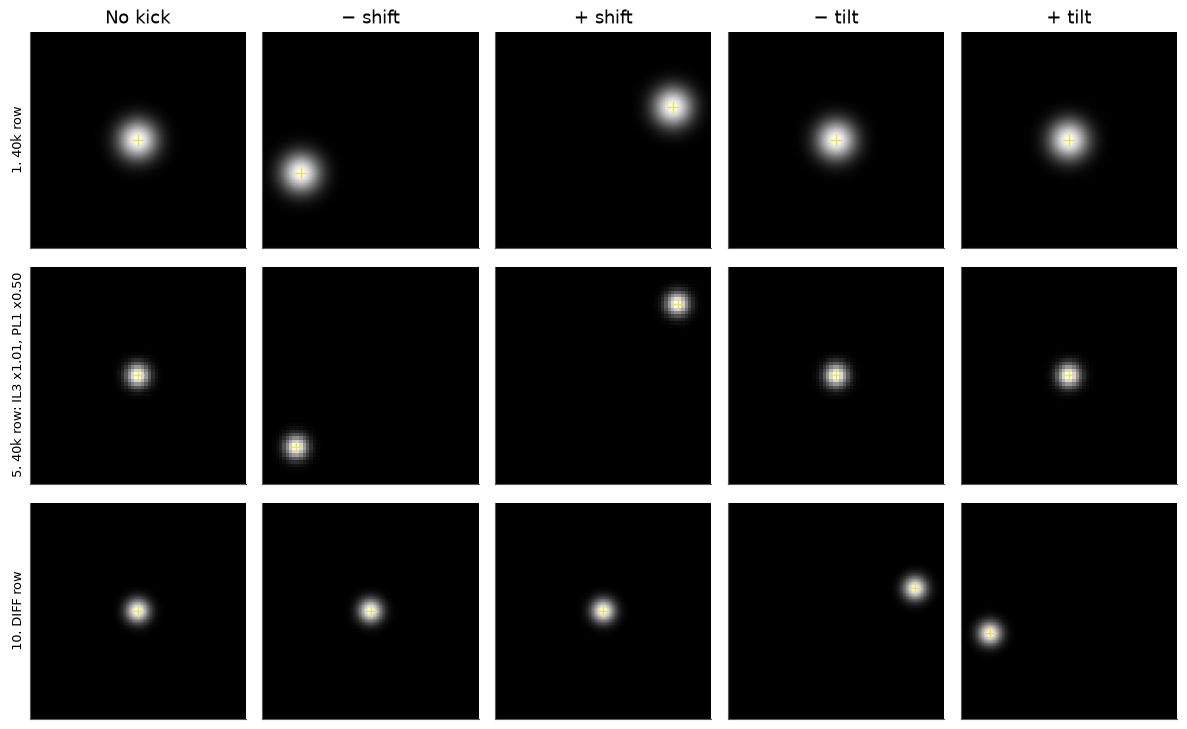

In [11]:
figures.frames(folder=recording.folder)

## 4. Fit the model

The fit tries both camera handednesses and pure or mixed deflectors, and keeps the simplest that
fits to the wobble. χ²/dof near 1 means it does; far above 1, the worst-fitting measurements say
which measurements to look at.

In [12]:
model = analyse.fit_projection_response(folder=recording.folder)
model

| projection-system response (unscaled) | |
|---|---|
| camera image mirrored | True |
| deflector y axis flipped | False |
| deflectors | pure |
| beam-position wobble (from the repeats) | 0.001 px |
| χ²/dof (≈ 1: fits to the wobble) | 0.66 |
| worst-fitting measurements | measurement 17 (DIFF row: IL2 x1.61, IL3 x1.01) tilt: 0.002 px; measurement 1 (40k row) shift: 0.001 px; measurement 20 (40k row) tilt: 0.001 px |

## 5. Does it predict lens settings it never saw?

Eight new settings, each a blend of three measured ones. The model predicts each beam move
before it is measured.

In [13]:
new = acquire.Recording(TEM3=TEM3, detector=detector,
                        folder="../generated/stage1_rehearsal/new_settings", settle_s=0)
new.take_over_lenses()
new.plan_new_settings(settings=analyse.new_settings(folder=recording.folder),
                      beam_move_px=50, test_kick_units=300, max_kick_units=20000)

opened ../generated/stage1_rehearsal/new_settings: microscope state saved (60 kV, X40000, CLA1 [32768, 32768], CLA2 [32768, 32768]); nothing changed


free-lens control on at the 40k row: IL1 21534, IL2 12814, IL3 18319, PL1 32985


planned measurements:


   1  new 0  kicks along x   IL1 18641, IL2 12284, IL3 18780, PL1 25669


   2  new 1  kicks along x   IL1 11818, IL2 12361, IL3 20077, PL1 16540


   3  new 2  kicks along x   IL1 15371, IL2 16700, IL3 19085, PL1 25237


... (2 outputs left out)

   6  new 5  kicks along x   IL1 16029, IL2 13325, IL3 19256, PL1 32985


   7  new 6  kicks along x   IL1 14355, IL2 14429, IL3 19252, PL1 32985


   8  new 7  kicks along x   IL1 10686, IL2 16845, IL3 19812, PL1 29152


kicks: a test kick of 300 units, then each +/- pair sized to move the beam about 50 px, at most 20000 units. The deflectors run 0-65535; centres CLA1 [32768, 32768], CLA2 [32768, 32768].


In [14]:
new.dark_frame()
new.measure_remaining()
new.restore()

first frame: 256x256, read as <i4, values -7 to 15 (if these look wrong, pass dtype='<u2' or similar)


dark frame: background 3.0


measurement 1 of 8


new 0: IL1 18641, IL2 12284, IL3 18780, PL1 25669 through free-lens control; waited 0 s


  frame without a kick: beam at (-0.0, -0.0) px from the centre, rms 3.4 px


  CLA1 (shift) test kick +300 along x: beam moved 1.11 px -> 13460 units to move it about 50 px


... (49 outputs left out)

  CLA1 (shift) kicks +4381 and -4381 along x: beam moved (+43.2, +25.1) and (-43.2, -25.1) px; CLA1 back to [32768, 32768]


  CLA2 (tilt) test kick +300 along x: beam moved 0.57 px -> 20000 units, the largest allowed (50 px would need 26492)


  CLA2 (tilt) kicks +20000 and -20000 along x: beam moved (+32.5, +18.9) and (-32.5, -18.9) px; CLA2 back to [32768, 32768]


restored: deflectors, free-lens control, blanking, function mode and HT as at opening; 8 of 8 measurements made, in ../generated/stage1_rehearsal/new_settings


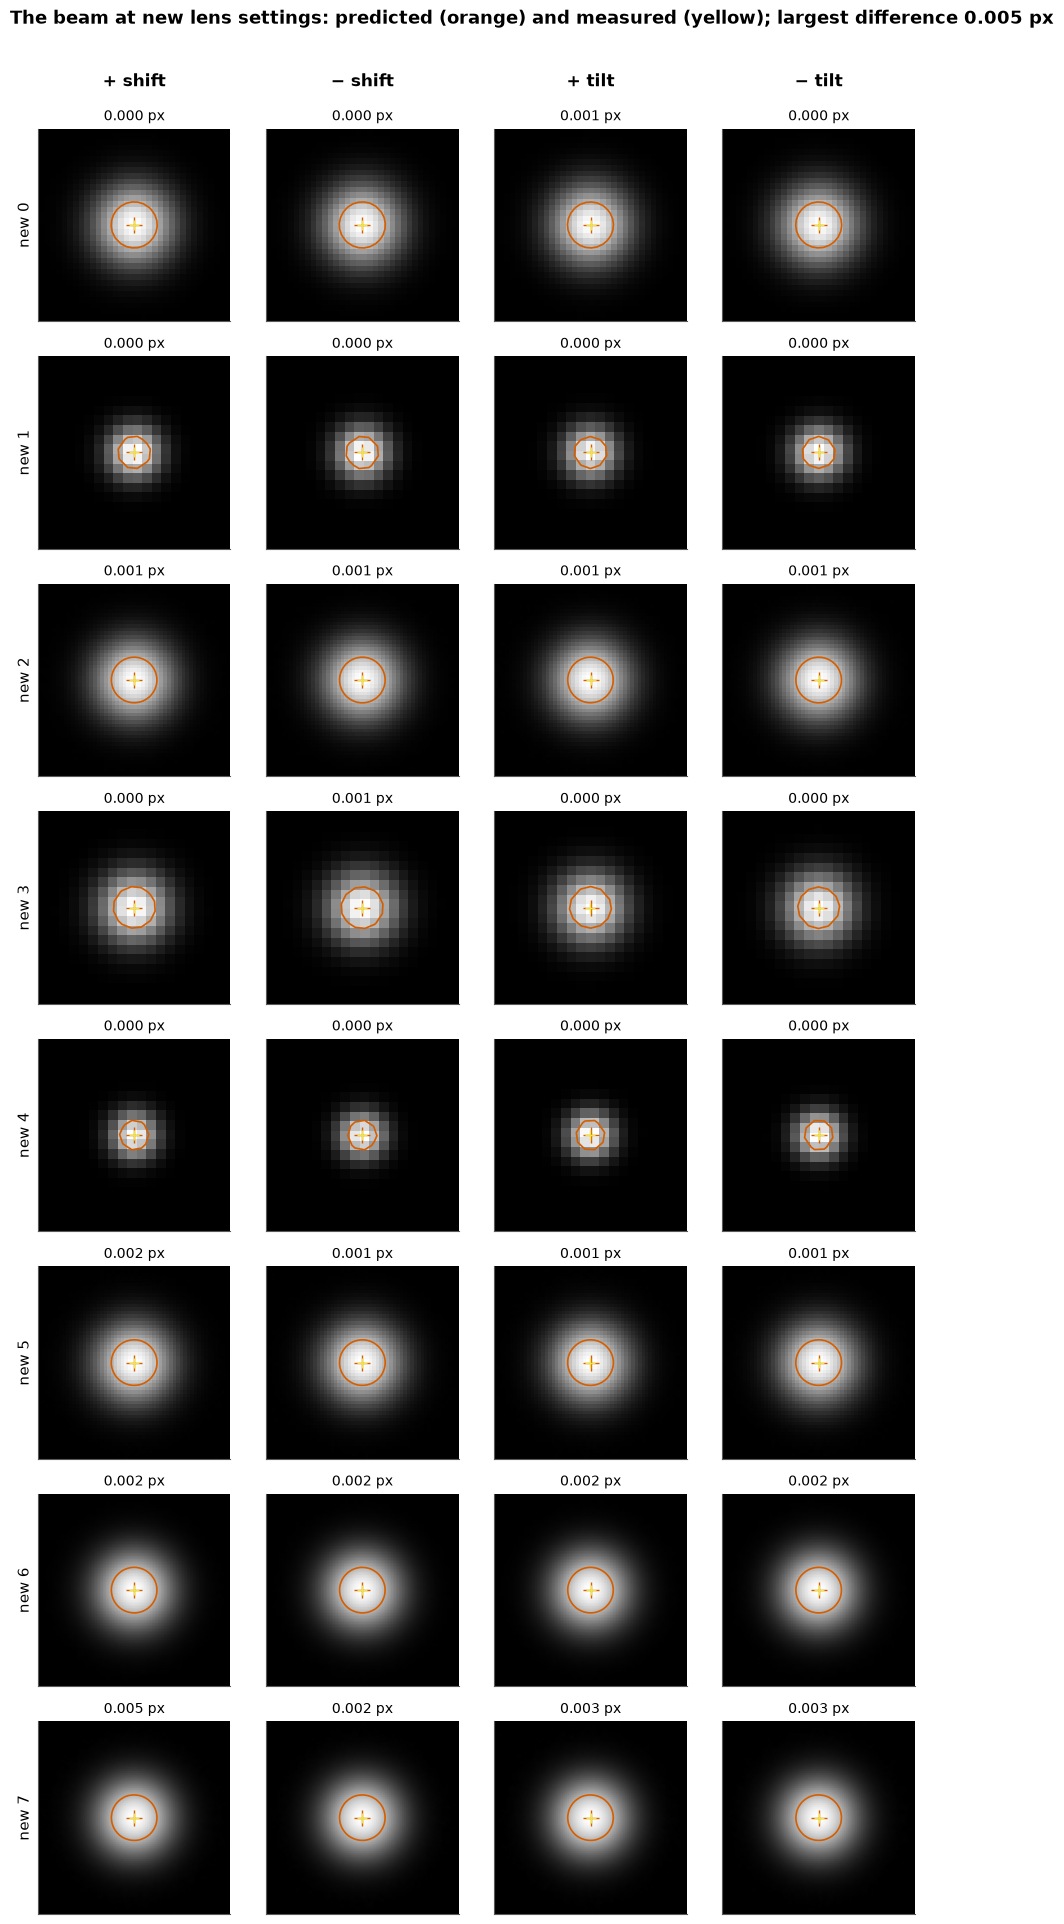

In [15]:
figures.prediction_test(model=model, folder=new.folder)

## Bring back from the real session

The recording folder, and the new-settings folder if there was time. Then
`analyse.fit_projection_response(folder=...)` and `analyse.compare(model=model, folder=...)`.